In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, classification_report, confusion_matrix, ConfusionMatrixDisplay, average_precision_score, precision_recall_curve
import seaborn as sns

### Random Forest

1. Load cleaned dataset

In [2]:
df = pd.read_csv('../Data/cleaned_flight_data.csv')
df.head()

,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,CRS_DEP_TIME,OP_UNIQUE_CARRIER,DEST,DISTANCE,CRS_ELAPSED_TIME,TAIL_NUM,FL_DATE,ARR_DEL15,DEP_HOUR,PREV_FLIGHT_DELAYED
0,2024,2,19,1,1957,G4,FLL,993.0,177.0,188NV,2024-02-19,1,19,0
1,2024,5,2,4,1536,G4,MYR,465.0,86.0,188NV,2024-05-02,0,15,0
2,2024,5,2,4,2017,G4,SFB,827.0,138.0,188NV,2024-05-02,0,20,0
3,2024,5,3,5,1642,G4,SFB,827.0,138.0,188NV,2024-05-03,0,16,0
4,2024,5,5,7,1536,G4,MYR,465.0,86.0,188NV,2024-05-05,0,15,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29281 entries, 0 to 29280
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 29281 non-null  int64  
 1   MONTH                29281 non-null  int64  
 2   DAY_OF_MONTH         29281 non-null  int64  
 3   DAY_OF_WEEK          29281 non-null  int64  
 4   CRS_DEP_TIME         29281 non-null  int64  
 5   OP_UNIQUE_CARRIER    29281 non-null  object 
 6   DEST                 29281 non-null  object 
 7   DISTANCE             29281 non-null  float64
 8   CRS_ELAPSED_TIME     29281 non-null  float64
 9   TAIL_NUM             29281 non-null  object 
 10  FL_DATE              29281 non-null  object 
 11  ARR_DEL15            29281 non-null  int64  
 12  DEP_HOUR             29281 non-null  int64  
 13  PREV_FLIGHT_DELAYED  29281 non-null  int64  
dtypes: float64(2), int64(8), object(4)
memory usage: 3.1+ MB


2. Split dataset into Training and Testing sets

In [4]:
# Feature variable
X = df[[
    "MONTH",
    "DAY_OF_MONTH",
    "DAY_OF_WEEK",
    "OP_UNIQUE_CARRIER",
    "DEST",
    "DISTANCE",
    "CRS_ELAPSED_TIME",
    "PREV_FLIGHT_DELAYED",
    "DEP_HOUR"
]]

# Target variable
y = df["ARR_DEL15"]

# Get dummy variables for categorical features
X = pd.get_dummies(X, columns=["OP_UNIQUE_CARRIER", "DEST"], drop_first=True)

In [5]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

3. Traing model

In [7]:
param_grid = {
    # Number of trees: 200 is a good sweet spot for RF
    'n_estimators': [100, 200, 300],
    
    # Depth: Prevent the trees from becoming too specific to training noise
    'max_depth': [10, 20, None],
    
    # Minimum samples needed to split: Higher values prevent overfitting
    'min_samples_split': [2, 5, 10],
    
    # Minimum samples in a leaf: Crucial for imbalanced data to ensure 
    # minority class patterns are statistically significant
    'min_samples_leaf': [1, 2, 4],
    
    # Max features: Controls diversity between trees
    'max_features': ['sqrt', 'log2']
}

# Initialize the classifier with class_weight='balanced'
rf = RandomForestClassifier(random_state=42, class_weight='balanced')

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='f1', # Optimized for the Precision-Recall Curve
    cv=5,                        # 5-fold cross-validation
    n_jobs=-1,                   # Use all available CPU cores
    verbose=2
)

# Fit the grid search
grid_search.fit(X_train, y_train)

# View the best parameters
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Average Precision: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best Parameters: {'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best Average Precision: 0.3880


In [19]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1))
])

param_grid = {
    'smote__sampling_strategy': [0.5, 0.75, 1.0],
    
    'rf__n_estimators': [200, 300],
    'rf__max_depth': [10, 15],           # Slightly deeper
    'rf__min_samples_split': [2, 5],         # Lower to 2
    'rf__min_samples_leaf': [1, 2],
    'rf__max_features': ['log2'],
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV F1 score: {grid_search.best_score_:.4f}")

# Evaluate
best_pipeline = grid_search.best_estimator_
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print(f"\nTest Set:")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters: {'rf__max_depth': 10, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 2, 'rf__n_estimators': 300, 'smote__sampling_strategy': 0.5}
Best CV F1 score: 0.3814

Test Set:
Recall:    0.4603
Precision: 0.2938
F1 Score:  0.3587
ROC-AUC:   0.6718


In [48]:
results = []
for t in np.arange(0.2, 0.61, 0.1):
    preds = (y_pred_proba >= t).astype(int)
    print(f'Threshold: {round(t, 2)}')
    print(f'Precision: {precision_score(y_test, preds):.4f}')
    print(f'Recall: {recall_score(y_test, preds):.4f}')
    print(f'F1: {f1_score(y_test, preds):.4f}')
    print()

print(pd.DataFrame(results))

Threshold: 0.2
Precision: 0.1698
Recall: 0.9990
F1: 0.2903

Threshold: 0.3
Precision: 0.1800
Recall: 0.9799
F1: 0.3041

Threshold: 0.4
Precision: 0.2237
Recall: 0.7166
F1: 0.3410

Threshold: 0.5
Precision: 0.2938
Recall: 0.4603
F1: 0.3587

Threshold: 0.6
Precision: 0.4007
Recall: 0.2472
F1: 0.3058

Empty DataFrame
Columns: []
Index: []


In [21]:
# Get the probabilities for the test set
y_probs = grid_search.best_estimator_.predict_proba(X_test)[:, 1]

# Calculate the Test Average Precision
test_ap = average_precision_score(y_test, y_probs)

print(f"Mean CV Average Precision: {grid_search.best_score_:.4f}")
print(f"Test Average Precision:    {test_ap:.4f}")

Mean CV Average Precision: 0.3814
Test Average Precision:    0.3306


In [22]:
# 1. Get precision, recall, and thresholds from the curve
precision, recall, thresholds = precision_recall_curve(y_test, y_probs)

# 2. Calculate F1 for every possible threshold
# We add a tiny epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# 3. Find the threshold that gave us the highest F1
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]

print(f"Best Threshold for F1-Score: {best_threshold:.4f}")

Best Threshold for F1-Score: 0.4641


In [27]:
best_pipeline = grid_search.best_estimator_
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

from sklearn.metrics import f1_score, average_precision_score, recall_score, precision_score, roc_auc_score

print("Metrics optimized for F1:")
print(f"  F1:               {f1_score(y_test, y_pred):.4f}")
print(f"  Avg Precision:    {average_precision_score(y_test, y_pred_proba):.4f}")
print(f"  Recall:           {recall_score(y_test, y_pred):.4f}")
print(f"  Precision:        {precision_score(y_test, y_pred):.4f}")
print(f"  ROC-AUC:          {roc_auc_score(y_test, y_pred_proba):.4f}")

Metrics optimized for F1:
  F1:               0.3587
  Avg Precision:    0.3306
  Recall:           0.4603
  Precision:        0.2938
  ROC-AUC:          0.6718


In [49]:
custom_threshold = 0.4641
y_custom_pred = (y_probs >= custom_threshold).astype(int)

# 3. Calculate metrics
prec = precision_score(y_test, y_custom_pred)
rec = recall_score(y_test, y_custom_pred)
f1 = f1_score(y_test, y_custom_pred)

print(f"--- Performance at Threshold: {custom_threshold} ---")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")

--- Performance at Threshold: 0.4641 ---
Precision: 0.2743
Recall:    0.5618
F1 Score:  0.3686


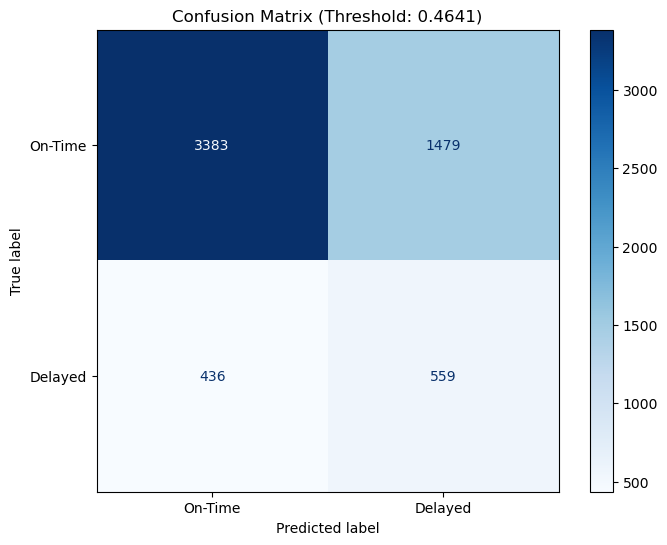

True Negatives (Correctly predicted On-Time): 3383
False Positives (False Alarms - Costly): 1479
False Negatives (Missed Delays): 436
True Positives (Caught Delays): 559


In [42]:
# 1. Apply your optimized threshold
opt_threshold = 0.4641
y_pred_opt = (y_probs >= opt_threshold).astype(int)

# 2. Create the confusion matrix
cm = confusion_matrix(y_test, y_pred_opt)

# 3. Plot the visual version
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['On-Time', 'Delayed'])
disp.plot(cmap='Blues', ax=ax)

plt.title(f'Confusion Matrix (Threshold: {opt_threshold})')
plt.show()

# 4. Print the raw numbers for your report
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (Correctly predicted On-Time): {tn}")
print(f"False Positives (False Alarms - Costly): {fp}")
print(f"False Negatives (Missed Delays): {fn}")
print(f"True Positives (Caught Delays): {tp}")

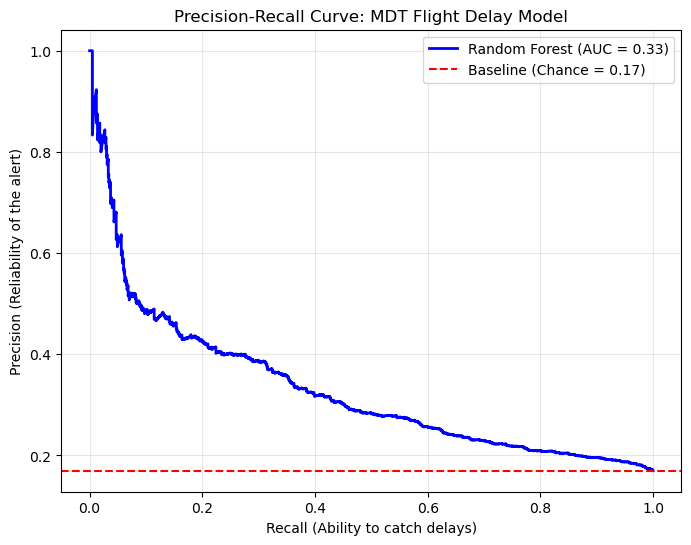

The PR-AUC is: 0.3301


In [43]:
from sklearn.metrics import precision_recall_curve, auc, PrecisionRecallDisplay
import matplotlib.pyplot as plt

# 1. Calculate the curve points
precision, recall, thresholds = precision_recall_curve(y_test, y_probs)

# 2. Calculate the Area Under the Curve (PR-AUC)
pr_auc = auc(recall, precision)

# 3. Plotting
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Random Forest (AUC = {pr_auc:.2f})', color='b', lw=2)

# Add a baseline (the percentage of delays in your test set)
baseline = y_test.sum() / len(y_test)
plt.axhline(y=baseline, color='r', linestyle='--', label=f'Baseline (Chance = {baseline:.2f})')

plt.xlabel('Recall (Ability to catch delays)')
plt.ylabel('Precision (Reliability of the alert)')
plt.title('Precision-Recall Curve: MDT Flight Delay Model')
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.show()

print(f"The PR-AUC is: {pr_auc:.4f}")

✓ ROC curve saved as 'roc_curve_rf.png'


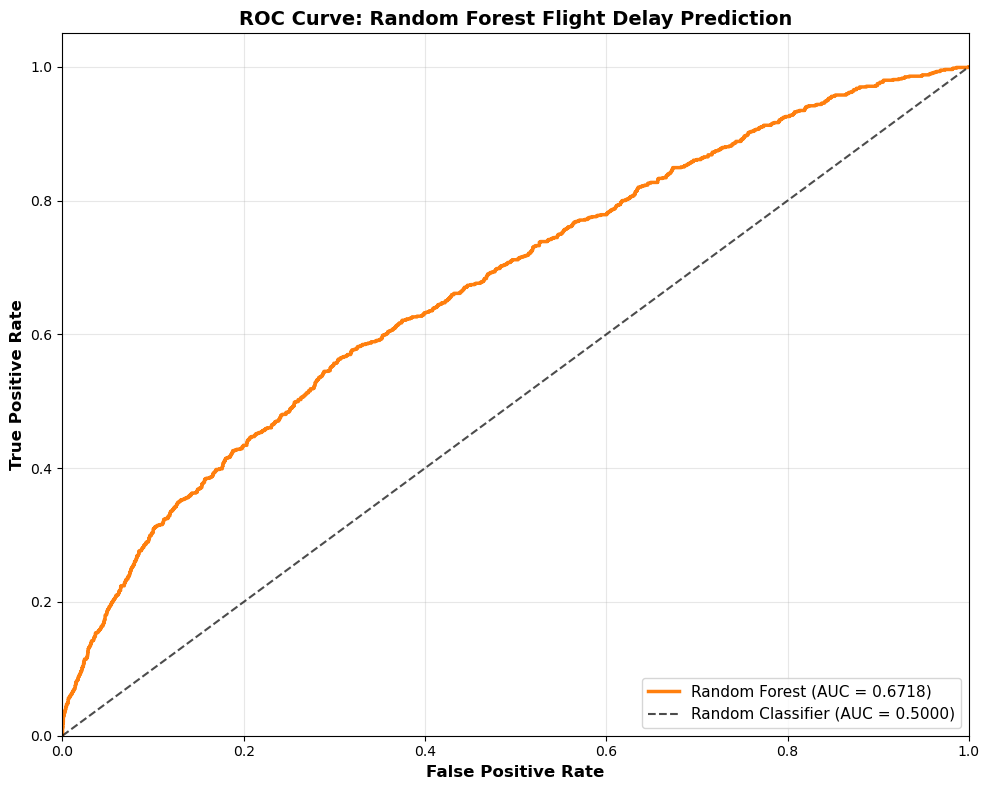

In [31]:
# Calculate ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)
 
# Plot
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc:.4f})', linewidth=2.5, color='#ff7f0e')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5000)', linewidth=1.5, alpha=0.7)
 
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title('ROC Curve: Random Forest Flight Delay Prediction', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(alpha=0.3)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.tight_layout()
plt.savefig('roc_curve_rf.png', dpi=300, bbox_inches='tight')
print("✓ ROC curve saved as 'roc_curve_rf.png'")
plt.show()

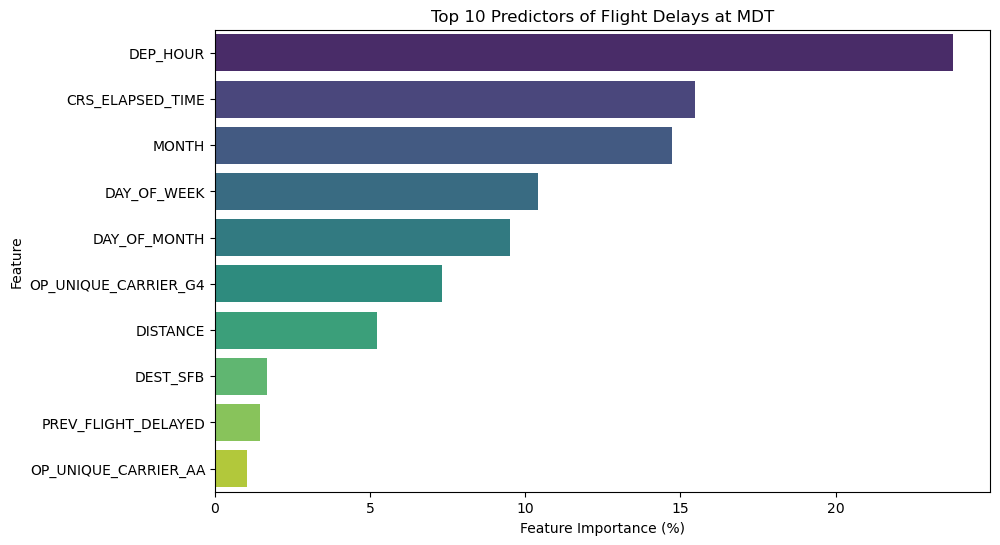

In [59]:
# 1. Get feature names (assuming X is your original DataFrame before it was split/scaled)
# If X doesn't work, try whatever your original DataFrame was called (e.g., df_clean)
try:
    feature_names = X.columns
except:
    # If X is gone, we'll have to manually list them or check the original df
    print("X is not a DataFrame. Please check the name of your original DataFrame.")

# 2. Extract importance
importances = best_pipeline.named_steps['rf'].feature_importances_

# 3. Create the DataFrame for plotting
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances*100})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(10)

# 4. Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, hue='Feature', palette='viridis', legend=False)
plt.title('Top 10 Predictors of Flight Delays at MDT')
plt.xlabel('Feature Importance (%)')
plt.show()

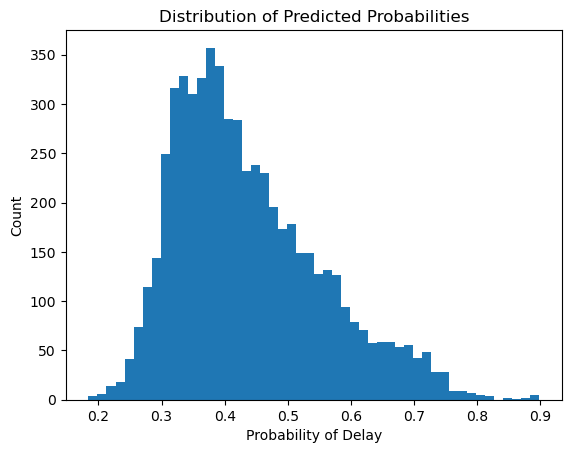

In [34]:
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

import matplotlib.pyplot as plt

plt.hist(y_prob, bins=50)
plt.title("Distribution of Predicted Probabilities")
plt.xlabel("Probability of Delay")
plt.ylabel("Count")
plt.show()